In [1]:
import lib_models as lb
import numpy as np
import pandas as pd

In [2]:
# pyright: reportAttributeAccessIssue=false, reportArgumentType=false

In [3]:
import pytorch_lightning as L 
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
from pytorch_lightning.loggers import TensorBoardLogger

[Tutorial how to use TensorBoard](https://docs.pytorch.org/tutorials/intermediate/tensorboard_tutorial.html)

[Documentation on using ModelCheckpoint](https://pytorch-lightning.readthedocs.io/en/1.0.8/generated/pytorch_lightning.callbacks.ModelCheckpoint.html)

There are 1697 recordings from S00 (in the processed database). Each has 5 band-wise adjacency matrices of ffDTF metric.

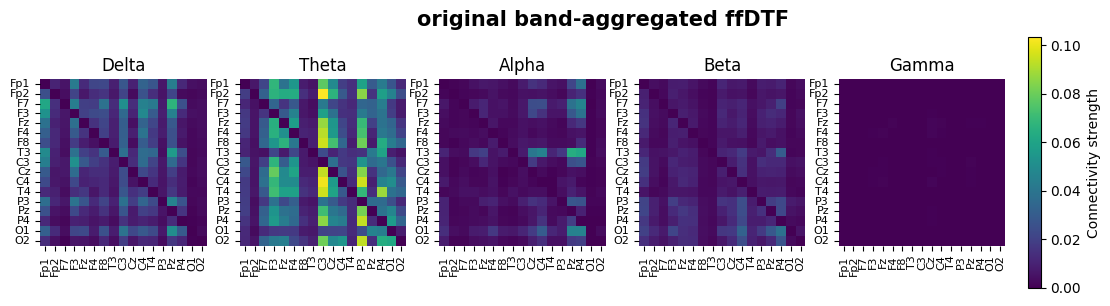

In [4]:
mm_conn, S00_exams_indices, N_S00_exams  = lb.load_s00_conn_memmap()
_ = lb.heatmap_bands(mm_conn[102][120]) #type:ignore

# data utilities

## dataset

Let's treat the bands dimension as colors in RGB

Create data splits with sklearn's [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html). The split was prepared once and saved to splits/ folder.

In [5]:
k = 0
with np.load("splits/s00.npz") as s: #type:ignore
    train_idx, val_idx, test_idx = s[f"fold{k}_train"], s[f"fold{k}_val"], s[f"fold{k}_test"]

In [6]:
import torch
from torch.utils.data import DataLoader
from lib_models import S00MILDataset

In [7]:
train_dataset = S00MILDataset(train_idx, max_instances=150,train=True) #type:ignore
val_dataset = S00MILDataset(val_idx, max_instances=150,train=False) #type:ignore
test_dataset = S00MILDataset(test_idx, max_instances=150, train=False) #type:ignore


In [8]:
train_loader = DataLoader(train_dataset, 
                          batch_size=10, 
                          shuffle=True,  
                          num_workers=8, 
                          pin_memory=True)

val_loader = DataLoader(val_dataset,  
                        batch_size=10, 
                        shuffle=False, 
                        num_workers=8, 
                        pin_memory=True)

test_loader = DataLoader(test_dataset, 
                         batch_size=10, 
                         shuffle=False, 
                         num_workers=8, 
                         pin_memory=True)

## let's see if the model works

In [9]:
from lib_models import ConvAE, BagEncoder

Quick sanity check before real training

In [10]:
x, y = next(iter(train_loader))
print(x.shape, x.dtype)                      # expect (N, W, 5, 17, 17), float32
assert x.shape[-2:] == (17, 17)

model = BagEncoder(ConvAE(latent=16))
model.eval()
with torch.no_grad():
    recon, z = model(x)
assert recon.shape == x.shape and z.shape == (x.shape[0], x.shape[1], 16)

torch.Size([10, 150, 5, 17, 17]) torch.float32


Smoke test that runs one train & one val epoch (bugs discovery)

In [11]:
trainer = L.Trainer(fast_dev_run=True, accelerator="auto")
trainer.fit(model, train_loader, val_loader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
Running in `fast_dev_run` mode: will run the requested loop using 1 batch(es). Logging and checkpointing is suppressed.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━╇━━━━━━━┩
│ 0 │ ae   │ ConvAE │ 37.3 K │ eval │     0 │
└───┴──────┴────────┴────────┴──────┴───────┘

Trainable params: 37.3 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 37.3 K                                                                                               
Total estimated model params size (MB): 0.149                                                                      
Modules in train mode: 0                                                                                           
Modules in eval mode: 16                                                                                           
Total FLOPs: 0

Output()

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/pytorch_lightning/loops/fit_loop.py:538: Found 17 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


`Trainer.fit` stopped: `max_steps=1` reached.


Overfit a tiny subset

In [ ]:
logger = TensorBoardLogger(save_dir="logs", name="model_1", version="overfit-2-batches-check") #type:ignore

In [ ]:
trainer = L.Trainer(overfit_batches=2,#type:ignore
                    max_epochs=100, 
                    accelerator="auto",
                    logger=logger)
model.train()
trainer.fit(model, train_loader, val_loader)

Train one fold

In [12]:
logger = TensorBoardLogger(save_dir="logs", name="model_1", version="train-run-fold0") #type:ignore

In [ ]:
logger = TensorBoardLogger(save_dir="logs", name="model_1", version="train-run-fold0") #type:ignore
ckpt = ModelCheckpoint(monitor="val_loss", mode="min", filename="ae_fold0") #type:ignore

trainer = L.Trainer(
    max_epochs=150,
    accelerator="auto",
    logger=logger,
    callbacks=[EarlyStopping(monitor="val_loss", patience=5), ckpt],
)

model = BagEncoder(ConvAE(latent=16))
trainer.fit(model, train_loader, val_loader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:881: Checkpoint directory logs/model_1/train-run-fold0/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ ae   │ ConvAE │ 37.3 K │ train │     0 │
└───┴──────┴────────┴────────┴───────┴───────┘

Trainable params: 37.3 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 37.3 K                                                                                               
Total estimated model params size (MB): 0.149                                                                      
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

In [ ]:
best = BagEncoder.load_from_checkpoint(ckpt.best_model_path, ae=ConvAE(latent=16))
pred_trainer = L.Trainer(accelerator="auto", logger=False, enable_checkpointing=False)
out = pred_trainer.predict(best, val_loader) 

In [ ]:
recons  = torch.cat([r for r, _ in out]) #type:ignore       
latents = torch.cat([z for _, z in out]) #type:ignore  

In [ ]:
compare_heatmaps(val_ds = val_dataset, 
                 connectivity_mm = mm_conn, 
                 reconstructed = recons, 
                 recon_i = 5, 
                 window_i = 45)

In [ ]:
compare_heatmaps(val_ds = val_dataset, 
                 connectivity_mm = mm_conn, 
                 reconstructed = recons, 
                 recon_i = 50, 
                 window_i = 120)

In [ ]:
compare_heatmaps(val_ds = val_dataset, 
                 connectivity_mm = mm_conn, 
                 reconstructed = recons, 
                 recon_i = 333, 
                 window_i = 20)

In [ ]:
compare_heatmaps(val_ds = val_dataset, 
                 connectivity_mm = mm_conn, 
                 reconstructed = recons, 
                 recon_i = 13, 
                 window_i = 87)

It seems that the most basic convolution autoencoder is good for identifying source vertical lines. It shows the tendency to overpower pixels that originally have lower values.